<a href="https://colab.research.google.com/github/htenaj8864-cmyk/Projec-NovaRetail/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 8 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df. head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `vistas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` y `satisfaccion` presentan un tipo de dato como decimal lo cual no es correcto se deben transformar en enteros.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df[['edad','satisfaccion']].describe()
df['edad'] = df['edad'].astype(int)
df['satisfaccion'] = df['satisfaccion'].round().astype(int)

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  int64  
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(3), int64(6), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
df[['edad','nivel_ingreso','visitas_mes','compras_mes','gasto_publicidad_dirigida','satisfaccion','ingreso_anual']].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.612400,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.741577,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,4.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` — La mitad de los clientes tienen 38 años de edad. El rango de clientes abarca de los 18 a los 75 años mostrando una base de usuarios madura y diversa.
- `nivel_ingreso` — Los ingresos varian desde los 8,000.00 hasta los 74,790.84 con una desviación estándar considerable de 9833.166 lo que nos muestra que el poder adquisitivo de los clientes es diverso.
- `visitas_mes` — En promedio los clientes visitan la plataforma 10 veces al mes, con un compartamiento que oscila entre 8 y 12 veces. El máximo de visitas es de 25.
- `compras_mes` — El promedio de compras al mes es de 1.2. Destaca que el 25% y el 50% se encuentran en 0 y 1 respectivamente, lo que significa que un porcentaje importante de visitantes navega frecuentemente pero compra con poca frecuencia. El máximo observado son 8 compras mensuales.
- `gasto_piblicidad_dirigida` — El gasto invertido en promedio por cliente es de 20.149301, con una media de 19.73 y un valor máximo de 75.51. el gato llega a comenzar en 0 para algunos clientes lo que significa que el presupuesto de publicidad es dirigido.
- `satisfaccion` — Con la media de 3.6124 y una mediana de 4, la percepción general del cliente tiende a la satisfacción positiva.
- `ingreso_anual` — El valor mínimo y el percentil 25% se sitúan en 0, lo que sugiere la presencia de registros sin ingresos anuales reportados o nulos, elevándose hasta un valor máximo de 244.69.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
df[['miembro_premium','abandono']].nunique()


miembro_premium    2
abandono           2
dtype: int64

In [ ]:
df[['miembro_premium','abandono']].describe()

,miembro_premium,abandono
count,15000.000000,15000.000000
mean,0.139267,0.150733
std,0.346236,0.357801
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,1.000000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — Tiene dos variables unicas 0=no y 1=si, pero también podemos observar que el 0.139267 son los clientes que cuentan con membresía.
- `abandono` — Tiene dos variables unicas 0=no y 1=si, se puede observar que 0.150733 de los clientes presentan estatus de abandono.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo','region']].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
df[['tipo_dispositivo','region']].value_counts()

tipo_dispositivo  region
móvil             norte     2843
                  oeste     2489
                  sur       2483
                  este      2003
escritorio        norte     1125
                  oeste      935
                  sur        894
                  este       766
tablet            norte      427
                  oeste      386
                  sur        349
                  este       300
dtype: int64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — El móvil es el dispositivo predominante con un total de 9,818 registros, seguido del escritorio con 3,720 y por último la tablet con 1,462 registros.
- `region` — La región Norte es la que mayor actividad presenta con 4,395 registros en total, seguida del Oeste con 3,810, después Sur con 3,726 registros, cifras muy ceracanas a Oeste y por último Este con 3,069 registros.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df.corr()
corr

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
edad,1.000000,-0.009003,0.004998,0.014971,0.000062,-0.003805,0.004605,-0.011500,0.017496
nivel_ingreso,-0.009003,1.000000,0.001060,0.007309,0.016834,-0.000625,-0.005598,0.005870,0.017446
visitas_mes,0.004998,0.001060,1.000000,0.353844,0.578947,0.000957,-0.012657,-0.008943,0.337147
compras_mes,0.014971,0.007309,0.353844,1.000000,0.207528,0.003042,0.003431,0.008291,0.967149
gasto_publicidad_dirigida,0.000062,0.016834,0.578947,0.207528,1.000000,-0.012203,0.002721,-0.004586,0.197483
satisfaccion,-0.003805,-0.000625,0.000957,0.003042,-0.012203,1.000000,0.024070,-0.021769,0.057420
miembro_premium,0.004605,-0.005598,-0.012657,0.003431,0.002721,0.024070,1.000000,-0.120488,0.093099
abandono,-0.011500,0.005870,-0.008943,0.008291,-0.004586,-0.021769,-0.120488,1.000000,-0.002824
ingreso_anual,0.017496,0.017446,0.337147,0.967149,0.197483,0.057420,0.093099,-0.002824,1.000000


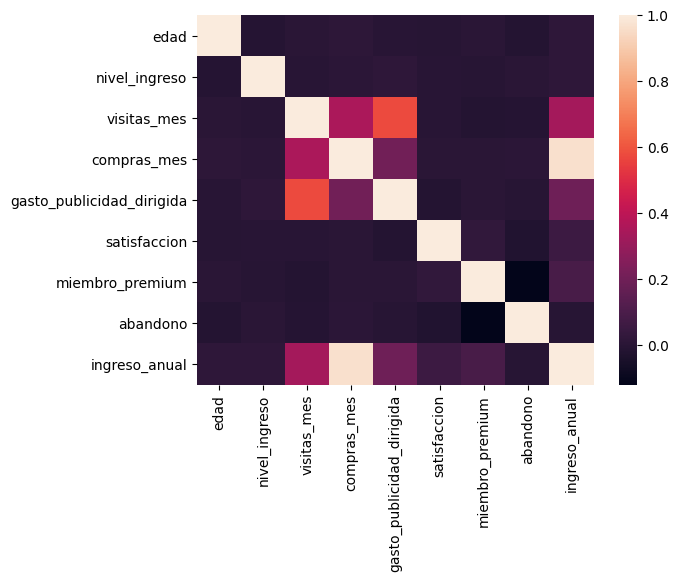

In [ ]:
sns.heatmap(corr)
plt.show()

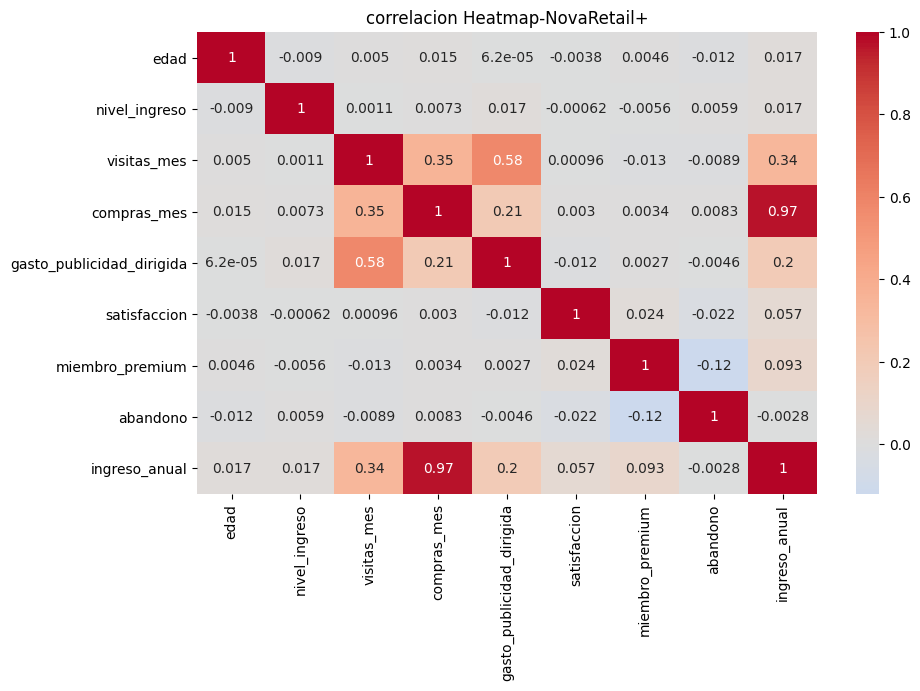

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True,cmap="coolwarm", center=0)
plt.title("correlacion Heatmap-NovaRetail+")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa que `gasto_publicidad_dirigida` y `visitas_mes` (0.58): Presentan una correlación positiva moderada. Esto sugiere que las estrategias de publicidad dirigida están cumpliendo su objetivo de incentivar y aumentar las visitas mensuales de los usuarios.
- `visitas_mes` y `compras_mes`(0.35) presenta una correlación positiva esto sugiere que a mayor visitas mayor frecuencia de compras.  
- `miembro_premium` y `abandono` (-0.12): Aunque baja, es una correlación negativa interesante; apunta a que los miembros premium tienen una ligera tendencia menor a abandonar la plataforma en comparación con los usuarios estándar.
-
Observaciones respecto a `ingreso_anual`  
- El `ingreso_anual` presenta una relación más fuerte con `compras_mes` (0.97) lo que sugiere que los clientes con mayor ingreso anual realizan una cantidad notablemente mayor de compras mensuales.
- `ingreso_anual` y `gasto_publicidad_dirigida` (0.2): nos sugiere que existe una ligera tendencia a dirigir mayor publicidad hacia perfiles de ingresos más altos.
- **Es importante resaltar que para validar si las variables dependen una de otra tenemos que realizar más observaciones exploratorias y no tomar la iformación como causalidad**


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

- No, ya que al generar un Scatterplot general tenemos más información y la mayoria de las variables no tienen relación como nos muestra el heatmap, sin embargo si realizaría mas especificamente las que nos muestran relación para evaluar más a profundidad las variables que si presentan una relación.

### Scatterplot para pares clave

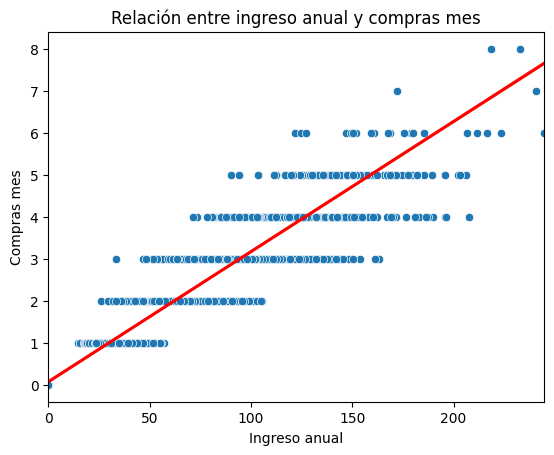

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df,x="ingreso_anual", y="compras_mes")
sns.regplot(data=df, x='ingreso_anual', y='compras_mes',
    scatter=False, color='red')
plt.title("Relación entre ingreso anual y compras mes")
plt.xlabel("Ingreso anual")
plt.ylabel("Compras mes")
plt.show()

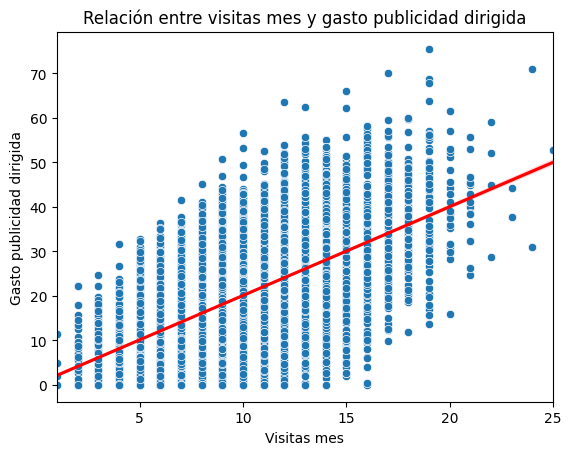

In [ ]:
sns.scatterplot(data=df,x="visitas_mes", y="gasto_publicidad_dirigida")
sns.regplot(data=df, x="visitas_mes", y="gasto_publicidad_dirigida",
    scatter=False, color='red')
plt.title("Relación entre visitas mes y gasto publicidad dirigida")
plt.xlabel("Visitas mes")
plt.ylabel("Gasto publicidad dirigida")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección positiva, dispersión media, baja o nula presencia de outliers y fuerte colinealidad.
-

**gasto_publicidad_dirigida vs visitas_mes**
- Dirección positiva, dispersión mea-alta, baja presencia de outliers y colinealidad moderada.
-

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
df['compras_mes'].corr(df['ingreso_anual'], method='pearson')

0.9671485435708564

In [ ]:
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='pearson')

0.5789472719412827

In [ ]:
# Calcular correlación entre variables relevantes
df['compras_mes'].corr(df['ingreso_anual'], method='spearman')

0.967482492032673

In [ ]:
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='spearman')

0.5592673242622609

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**compras_mes vs ingreso_anual**
- Correlación entre compras_mes vs ingreso_anual
- Dirección: Positiva, ya que ambos coeficientes son mayores a cero.
- Magnitud: Muy alta. Tanto Pearson (0.967) como Spearman (0.967) se ubican extremadamente cerca de 1, lo que indica una relación lineal y monótona casi perfecta entre los ingresos y la frecuencia de compras.
- Posible colinealidad: Extremadamente alta. Al estar tan cerca de 1, existe una fuerte redundancia informativa. Esto significa que ambas variables explican prácticamente lo mismo, por lo que incluirlas conjuntamente en un modelo de regresión podría generar problemas severos de multicolinealidad.

**gasto_publicidad_dirigida vs visitas_mes**
- Correlación entre gasto_publicidad_dirigida vs vistas_mes.
- Dirección: Positiva, reflejando que a mayor inversión publicitaria, mayor es el volumen de visitas.
- Magnitud: Moderada a alta. Pearson arroja un valor de ~0.579 y Spearman de ~0.559, lo que demuestra una tendencia clara pero con un nivel considerable de dispersión entre los puntos individuales.
- Posible colinealidad: Moderada. No representa un riesgo crítico de redundancia para un modelo predictivo, por lo que ambas variables pueden coexistir sin afectar la estabilidad del análisis.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
df["miembro_premium"] = df["miembro_premium"].replace({ "Yes": 1,"No": 0})
pointbiserialr( df["miembro_premium"], df["ingreso_anual"] )

SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)

In [ ]:
df["abandono"] = df["abandono"].replace({ "Yes": 1,"No": 0})
pointbiserialr( df["abandono"], df["ingreso_anual"] )

SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**var1 vs var2**
- Relación entre miembro_premium vs ingreso_anual.
- Dirección: Positiva, ya que el estadístico es mayor a cero (0.093). Esto indica que tener una membresía premium se asocia de forma ligera con un mayor ingreso anual.
- Magnitud: Baja, al encontrarse muy cerca de cero (0.093). Aunque cuenta con significancia estadística debido a un p-valor extremadamente bajo y  la fuerza de la relación en términos prácticos es débil.
  
**var2 vs var3**
- Relación entre abandono vs ingreso_anual.
- Dirección: Negativa, dado que el estadístico es menor a cero (-0.0028).
- Magnitud: Baja / Nula, ya que el valor está prácticamente en cero (-0.0028) y su p-valor es alto (0.729). Esto sugiere que no existe una relación lineal real ni estadísticamente significativa entre el ingreso anual de los clientes y su tasa de abandono.   

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
tabla = pd.crosstab(df["region"],df["tipo_dispositivo"])
tabla

tipo_dispositivo,escritorio,móvil,tablet
region,,,
este,766,2003,300
norte,1125,2843,427
oeste,935,2489,386
sur,894,2483,349


In [ ]:
chi2, p, dof, expected = chi2_contingency(tabla)
chi2

4.596697852095489

In [ ]:
# Aplicar V de Cramér en variables relevantes
n = tabla.sum().sum()

cramers_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
cramers_v

0.012378338407739397

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér-
- Al observar que el resultado de Cramér V es muy cercano a cero esto nos sugiere que no hay un patron claro entre las categorías,, lo que indica es que la asociación entre región y tipo de dispositivo no varia de manera relevante según la región, por lo que no hay un patrón que justifique estrategias distintas por región.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — Frecuencia de compras y su fuerte asociación con el ingreso anual

**Evidencia visual:** El diagrama de dispersión (scatterplot) con línea de tendencia muestra una pendiente ascendente muy marcada, con una concentración uniforme de los puntos y una dispersión acotada alrededor de la recta, evidenciando una fuerte linealidad.  ![image.png](attachment:31010ed4-7cad-40f3-910b-ecd41a39a08e.png)

**Evidencia numérica:**
- Coeficiente de correlación de Pearson: 0.967
- Coeficiente de correlación de Spearman: 0.967

**Interpretación**  
- Existe una relación lineal y monótona casi perfecta entre el número de compras mensuales (compras_mes) y el ingreso anual generado por el cliente (ingreso_anual). Lo que sugiere que los clientes que realizan un mayor volumen de transacciones mensuales son, consistentemente, aquellos que reportan el mayor ingreso anual para la plataforma.

**No podemos afirmar**  
- No podemos concluir que incrementar artificialmente las compras (por ejemplo, mediante notificaciones masivas o descuentos forzados) vaya a causar un aumento proporcional en el ingreso anual, ni que el ingreso anual dependa exclusivamente de esta variable de manera aislada (existe una alta colinealidad informativa).

**Implicación de negocio**  
- Dado que la frecuencia de transacciones es el indicador con mayor correlación con los ingresos, el equipo de Crecimiento debe enfocar sus esfuerzos de retención en programas de lealtad transaccional y recordatorios personalizados de compra para mantener activos a los usuarios de mayor valor, evitando saturar los modelos predictivos con ambas variables de forma simultánea debido a la redundancia estadística.



### Hallazgo 2 — Impacto del gasto en publicidad dirigida sobre las visitas mensuales

**Evidencia visual:**
- El scatterplot entre visitas mensuales y gasto en publicidad dirigida muestra una tendencia positiva clara, aunque con una dispersión media-alta que refleja variabilidad en la respuesta de los usuarios ante los estímulos publicitarios. ![image.png](attachment:33808647-80ff-48f7-bf5b-1c052a7f5c4a.png)
  
**Evidencia numérica:**
- Coeficiente de Pearson: 0.579
- Coeficiente de Spearman: 0.559
  
**Interpretación**  
- Se observa una correlación positiva moderada-alta. Los usuarios a los que se les asigna un mayor presupuesto de publicidad dirigida tienden a registrar un mayor número de visitas mensuales a la plataforma web o aplicación.

**No podemos afirmar**  
- No podemos asegurar que la publicidad sea la única causa del tráfico a la plataforma, ni que un mayor gasto en pauta garantice por sí solo una conversión efectiva en compras o ingresos anuales directos.

**Implicación de negocio**  
- La estrategia de asignación de presupuesto publicitario está cumpliendo su propósito de incentivar el tráfico y la interacción en la plataforma (visitas_mes). Sin embargo, es necesario optimizar la eficiencia del gasto publicitario (gasto_publicidad_dirigida), evaluando el Retorno de Inversión (ROI) por segmento para asegurar que el tráfico atraído se traduzca efectivamente en transacciones.


### Hallazgo 3 — Relación entre la membresía Premium, el abandono y el ingreso

**Evidencia numérica:**
- Asociación miembro_premium vs ingreso_anual (Punto-biserial): Estadístico = 0.093 (p-valor < 0.001).
- Asociación abandono vs ingreso_anual (Punto-biserial): Estadístico = -0.0028 (p-valor = 0.729).
- Asociación region vs tipo_dispositivo (V de Cramér): 0.0124 (asociación prácticamente nula).
  
**Interpretación**  
- Poseer una membresía premium muestra una ligera tendencia positiva con el ingreso anual, aunque su fuerza práctica es baja a pesar de ser estadísticamente significativa debido al tamaño de la muestra (15,000).
- La tasa de abandono (abandono) no muestra ninguna relación lineal ni estadística con el ingreso anual de los clientes.
- La distribución de los tipos de dispositivo no varía de manera relevante entre las distintas regiones geográficas.

**No podemos afirmar**  
-  No podemos asumir que los usuarios con membresía premium generen por sí solos la mayor parte de los ingresos, ni que los clientes con mayores ingresos sean inmunes al abandono de la plataforma.

**Implicación de negocio**  
- Las estrategias de retención y prevención de abandono deben aplicarse de forma transversal a toda la base de usuarios y no segmentarse únicamente en función del ingreso anual del cliente. Asimismo, las campañas de marketing digital pueden estandarizarse por tipo de dispositivo sin necesidad de hiper-segmentarlas por región geográfica, ya que el comportamiento tecnológico es homogéneo.
